# Data scarcity: Ignatov's CNN vs FIN and FIN + 40, pretrained vs random init, 7 labelled WISDM users

- for each seed 0-4, 9 random users: the first 7 train, the next 2 are the validation users, the remaining 27 are the test set
- **FIN, pretrained:** imitates spectral entropy, autocorrelation peak and spectral peak on 30,000 warped copies of the 7 users' windows (no labels), then stays frozen; only the head learns
- **FIN, random init:** the same architecture with random weights, trained end-to-end
- **FIN + 40, pretrained / random init:** the same plus Ignatov's 40 statistical features (standardised with the training users' statistics) next to the FIN embeddings; the pretrained FIN imitates on the 7 users' real windows plus the 30,000 warped copies
- **Ignatov's CNN** (`ClassicML/cnn_wisdm.py`): Conv1D 196 filters of 12 -> max-pool 4 -> + his 40 statistical features -> Dense 1024 (L2) -> dropout 85 % -> softmax, Adam 5e-4; per-axis mean removed from each window, then, as in his code, hstack(x, y, z) reshaped to (200, 3), so the convolution slides along x, then y, then z with 3 consecutive samples as channels, the 40 features standardised with the training users' statistics
- **Ignatov's CNN + 3 FIN features:** the same CNN with the FIN's three targets (spectral entropy, autocorrelation peak, spectral peak) of each axis, 9 numbers, in place of the 40 statistical features
- FIN classifier: FIN embedding of each axis (+ the 40 features for FIN + 40) -> Dense 128 -> dropout 50 % -> softmax
- all train 150 epochs with batch 256; test accuracy at the best validation epoch and at the last epoch
- the last cell draws the paper's figure (`scarcity_panels`) from the same run's test curves


In [1]:
import os
import sys
import warnings
    
os.environ["KERAS_BACKEND"] = "torch"
warnings.filterwarnings("ignore")
FIN = os.path.dirname(os.getcwd())
sys.path[:0] = [FIN, os.path.join(FIN, "FIN-classifiers"), os.path.join(FIN, "data-processing")]

import keras
import numpy as np
import pandas as pd
import torch
from keras import layers, ops
from sklearn.metrics import f1_score

import config as cfg
import wisdm_windowing as ww
from augmentation import make
from bilin_fin_temporal_plus_original import RhythmFIN, ignatov_features, targets

SEEDS = (0, 1, 2, 3, 4)
N_TRAIN = 7
N_VAL = 2
EPOCHS = 150
N_SYNTH = 30000

## Data

In [2]:
windows, users, labels = ww.window_raw()
candidates = np.setdiff1d(np.unique(users), [30])
stats = ignatov_features(windows)  # 40 statistical features of every window
# the FIN's 3 targets (spectral entropy, AC peak, spectral peak) of x, y and z: 9 features
fin_features = np.concatenate([targets(windows[:, a].astype(np.float64)) for a in range(len(cfg.AXES))], axis=1)
print(f"{len(windows)} windows, {len(np.unique(users))} users")


10367 windows, 36 users


## Models

In [3]:
class Accuracy(keras.callbacks.Callback):
    """Accuracy and cross-entropy loss on each named (x, y) set after every epoch (dropout off), and the
    weights of the best "val" epoch. Restores the RNG so training is unaffected."""

    def __init__(self, **sets):
        super().__init__()
        self.sets, self.curves = sets, {key: [] for name in sets for key in (name, name + " loss")}
        self.best_epoch, self.best_weights = 0, None

    def on_epoch_end(self, epoch, logs=None):
        rng = torch.random.get_rng_state()
        for name, (x, y) in self.sets.items():
            prob = self.model.predict(x, batch_size=1024, verbose=0)
            self.curves[name].append(float(np.mean(prob.argmax(axis=1) == y)))
            self.curves[name + " loss"].append(float(-np.mean(np.log(np.clip(prob[np.arange(len(y)), y], 1e-7, 1)))))
        torch.random.set_rng_state(rng)
        if self.curves["val"][-1] > max(self.curves["val"][:-1], default=-1):
            self.best_epoch, self.best_weights = epoch + 1, self.model.get_weights()


def pretrain(axes, seed):
    keras.utils.set_random_seed(seed)
    fin = RhythmFIN()
    y = targets(axes)
    fin.compile(optimizer=keras.optimizers.Adam(cfg.FIN_LR), loss="mse")
    fin.fit(axes, ((y - y.mean(0)) / y.std(0)).astype(np.float32),
            epochs=cfg.FIN_EPOCHS, batch_size=cfg.BATCH_SIZE, verbose=0)
    return fin.get_weights()


class FINClassifier(keras.Model):
    """inputs: [windows, extra features]; the extra features may have 0 columns (FIN alone)."""

    def __init__(self, fin, **kw):
        super().__init__(**kw)
        self.fin = fin
        self.hidden = layers.Dense(cfg.HEAD_WIDTH, activation="relu")
        self.drop = layers.Dropout(0.5)
        self.out = layers.Dense(cfg.N_CLASSES, activation="softmax")

    def call(self, inputs, training=None):
        x, extra = inputs
        parts = [self.fin.embed(x[:, i, :]) for i in range(len(cfg.AXES))]
        h = self.hidden(ops.concatenate(parts + ([extra] if extra.shape[-1] else []), axis=1))
        return self.out(self.drop(h, training=training))


def ignatov_cnn(n_features):
    """Ignatov's CNN as in ClassicML/cnn_wisdm.py."""
    init = dict(kernel_initializer=keras.initializers.TruncatedNormal(stddev=0.01),
                bias_initializer=keras.initializers.Constant(0.01))
    l2 = keras.regularizers.L2(5e-4 / 2 / 200)
    signal = keras.Input((cfg.SEGMENT, len(cfg.AXES)))
    features = keras.Input((n_features,))
    h = layers.Conv1D(196, 12, padding="same", activation="relu", **init)(signal)
    h = layers.MaxPooling1D(4, padding="same")(h)
    h = layers.Concatenate()([layers.Flatten()(h), features])
    h = layers.Dense(1024, activation="relu", kernel_regularizer=l2, bias_regularizer=l2, **init)(h)
    h = layers.Dropout(0.85)(h)  # his code feeds keep_prob = 0.15: 85 % dropped
    return keras.Model([signal, features], layers.Dense(cfg.N_CLASSES, activation="softmax", **init)(h))


def fit(model, x, lr, tr, va, te, batch_size=cfg.BATCH_SIZE):
    """x: the model input for every window (an array or a list of arrays). Returns the test predictions at the
    best validation epoch and at the last epoch, the accuracy curves and the best epoch."""
    pick = lambda m: [a[m] for a in x] if isinstance(x, list) else x[m]
    track = Accuracy(train=(pick(tr), labels[tr]), val=(pick(va), labels[va]), test=(pick(te), labels[te]))
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy")
    model.fit(pick(tr), labels[tr], epochs=EPOCHS, batch_size=batch_size, verbose=0, callbacks=[track])
    last = model.predict(pick(te), batch_size=1024, verbose=0).argmax(axis=1)
    model.set_weights(track.best_weights)
    best = model.predict(pick(te), batch_size=1024, verbose=0).argmax(axis=1)
    return best, last, track.curves, track.best_epoch


def run_fin(tr, va, te, seed, pretrained, with_stats=False):
    """FIN classifier on the windows, with_stats: plus the 40 statistical features. pretrained: the FIN imitates the
    rhythm features on N_SYNTH warped copies of the 7 training users' windows (with_stats: plus the real windows),
    then stays frozen; otherwise random weights, trained with the head."""
    if with_stats:
        mu, sd = stats[tr].mean(0), stats[tr].std(0)
        extra = ((stats - mu) / np.where(sd < 1e-8, 1.0, sd)).astype(np.float32)
    else:
        extra = np.zeros((len(windows), 0), np.float32)
    if pretrained:
        real = windows[tr].reshape(-1, cfg.SEGMENT)
        warp = make(N_SYNTH, seed, real)
        weights = pretrain(np.concatenate([real, warp]) if with_stats else warp, seed)
    keras.utils.set_random_seed(seed)
    fin = RhythmFIN()
    if pretrained:
        fin(np.zeros((1, cfg.SEGMENT), np.float32))
        fin.set_weights(weights)
        fin.trainable = False
    keras.utils.set_random_seed(seed)
    return fit(FINClassifier(fin), [windows, extra], cfg.HEAD_LR, tr, va, te)


def run_ignatov(tr, va, te, seed, features=None):
    """Ignatov's CNN; features: the extra inputs of every window, his 40 statistical features by default."""
    features = stats if features is None else features
    x = windows - windows.mean(axis=2, keepdims=True)
    x = x.reshape(len(x), cfg.SEGMENT, len(cfg.AXES)).astype(np.float32)
    mu, sd = features[tr].mean(0), features[tr].std(0)
    f = ((features - mu) / np.where(sd < 1e-8, 1.0, sd)).astype(np.float32)
    keras.utils.set_random_seed(seed)
    return fit(ignatov_cnn(f.shape[1]), [x, f], 5e-4, tr, va, te)

## Experiment

In [4]:
MODELS = {
    "Ignatov CNN + 40 statistical": run_ignatov,
    "Ignatov CNN + 3 FIN features": lambda tr, va, te, seed: run_ignatov(tr, va, te, seed, fin_features),
    "FIN, random init": lambda tr, va, te, seed: run_fin(tr, va, te, seed, pretrained=False),
    "FIN, pretrained": lambda tr, va, te, seed: run_fin(tr, va, te, seed, pretrained=True),
    "FIN + 40, random init": lambda tr, va, te, seed: run_fin(tr, va, te, seed, pretrained=False, with_stats=True),
    "FIN + 40, pretrained": lambda tr, va, te, seed: run_fin(tr, va, te, seed, pretrained=True, with_stats=True),
}
KEYS = {"Ignatov CNN + 40 statistical": "ignatov_cnn", "Ignatov CNN + 3 FIN features": "ignatov_cnn_fin3",
        "FIN, random init": "fin_random", "FIN, pretrained": "fin_warped",
        "FIN + 40, random init": "fin40_random", "FIN + 40, pretrained": "fin40_pretrained"}

rows, curves = [], {model: [] for model in MODELS}
for seed in SEEDS:
    picked = np.random.default_rng(seed).choice(candidates, N_TRAIN + N_VAL, replace=False)
    tr, va = np.isin(users, picked[:N_TRAIN]), np.isin(users, picked[N_TRAIN:])
    te = ~(tr | va)
    truth = labels[te]
    for model, run in MODELS.items():
        best, last, curve, epoch = run(tr, va, te, seed)
        curves[model].append(curve["test"])
        rows.append({"seed": seed, "model": model, "best epoch": epoch,
                     "accuracy": np.mean(best == truth), "macro F1": f1_score(truth, best, average="macro"),
                     "accuracy, last epoch": np.mean(last == truth),
                     "macro F1, last epoch": f1_score(truth, last, average="macro")})
    print(f"seed {seed}: train {sorted(picked[:N_TRAIN].tolist())}, val {sorted(picked[N_TRAIN:].tolist())} done",
          flush=True)
results = pd.DataFrame(rows)


seed 0: train [3, 7, 9, 10, 15, 18, 23], val [1, 2] done


seed 1: train [2, 5, 9, 13, 15, 29, 34], val [22, 28] done


seed 2: train [4, 8, 9, 12, 13, 23, 35], val [15, 27] done


seed 3: train [2, 3, 8, 20, 26, 29, 32], val [6, 22] done


seed 4: train [3, 16, 20, 27, 31, 34, 36], val [26, 33] done


In [5]:
cols = ["accuracy", "macro F1", "accuracy, last epoch", "macro F1, last epoch"]
g = results.groupby("model")[cols]
display((g.mean().map("{:.3f}".format) + " Ã‚Â± " + g.std().map("{:.3f}".format)).loc[list(MODELS)],
        results.pivot(index="seed", columns="model", values=["best epoch", "accuracy"]).round(3))


,accuracy,macro F1,"accuracy, last epoch","macro F1, last epoch"
model,,,,
Ignatov CNN + 40 statistical,0.813 Ã‚Â± 0.063,0.692 Ã‚Â± 0.201,0.836 Ã‚Â± 0.037,0.797 Ã‚Â± 0.033
Ignatov CNN + 3 FIN features,0.814 Ã‚Â± 0.039,0.699 Ã‚Â± 0.121,0.834 Ã‚Â± 0.028,0.771 Ã‚Â± 0.025
"FIN, random init",0.786 Ã‚Â± 0.071,0.611 Ã‚Â± 0.198,0.804 Ã‚Â± 0.025,0.696 Ã‚Â± 0.018
"FIN, pretrained",0.839 Ã‚Â± 0.016,0.727 Ã‚Â± 0.023,0.832 Ã‚Â± 0.028,0.727 Ã‚Â± 0.037
"FIN + 40, random init",0.841 Ã‚Â± 0.042,0.759 Ã‚Â± 0.061,0.861 Ã‚Â± 0.020,0.802 Ã‚Â± 0.015
"FIN + 40, pretrained",0.868 Ã‚Â± 0.025,0.790 Ã‚Â± 0.039,0.887 Ã‚Â± 0.011,0.823 Ã‚Â± 0.017


best epoch                                        \
model FIN + 40, pretrained FIN + 40, random init FIN, pretrained   
seed                                                               
0                     10.0                   9.0           111.0   
1                    143.0                 149.0            35.0   
2                     24.0                   8.0            23.0   
3                     18.0                  79.0            67.0   
4                      4.0                  13.0            10.0   

                                                     \
model FIN, random init Ignatov CNN + 3 FIN features   
seed                                                  
0                  3.0                          6.0   
1                 34.0                         21.0   
2                 17.0                         22.0   
3                  7.0                         39.0   
4                133.0                         34.0   

                                               accuracy                        \
model Ignatov CNN + 40 statistical FIN + 40, pretrained FIN + 40, random init   
seed                                                                            
0                              2.0                0.848                 0.782   
1                             39.0                0.884                 0.866   
2                             10.0                0.884                 0.811   
3                             25.0                0.889                 0.873   
4                             24.0                0.833                 0.873   

                                                                     \
model FIN, pretrained FIN, random init Ignatov CNN + 3 FIN features   
seed                                                                  
0               0.835            0.666                        0.748   
1               0.818            0.815                        0.839   
2               0.847            0.781                        0.820   
3               0.861            0.818                        0.817   
4               0.835            0.850                        0.846   

                                    
model Ignatov CNN + 40 statistical  
seed                                
0                            0.705  
1                            0.856  
2                            0.813  
3                            0.843  
4                            0.849

## Figure

Test accuracy per epoch, mean Â± s.d. over the seeds, first 50 epochs: (a) without, (b) with the 40 statistical features. Saves `data_scarcity_curves.npz` and `scarcity_panels.eps` next to this notebook.

saved C:\Users\amanb\PycharmProjects\arsu-labs-action-recognition\Feature-Imitating-Network\data-scarcity\scarcity_panels.eps
saved C:\Users\amanb\PycharmProjects\arsu-labs-action-recognition\Feature-Imitating-Network\data-scarcity\scarcity_panels.pdf


saved C:\Users\amanb\PycharmProjects\arsu-labs-action-recognition\Feature-Imitating-Network\data-scarcity\scarcity_panels.png


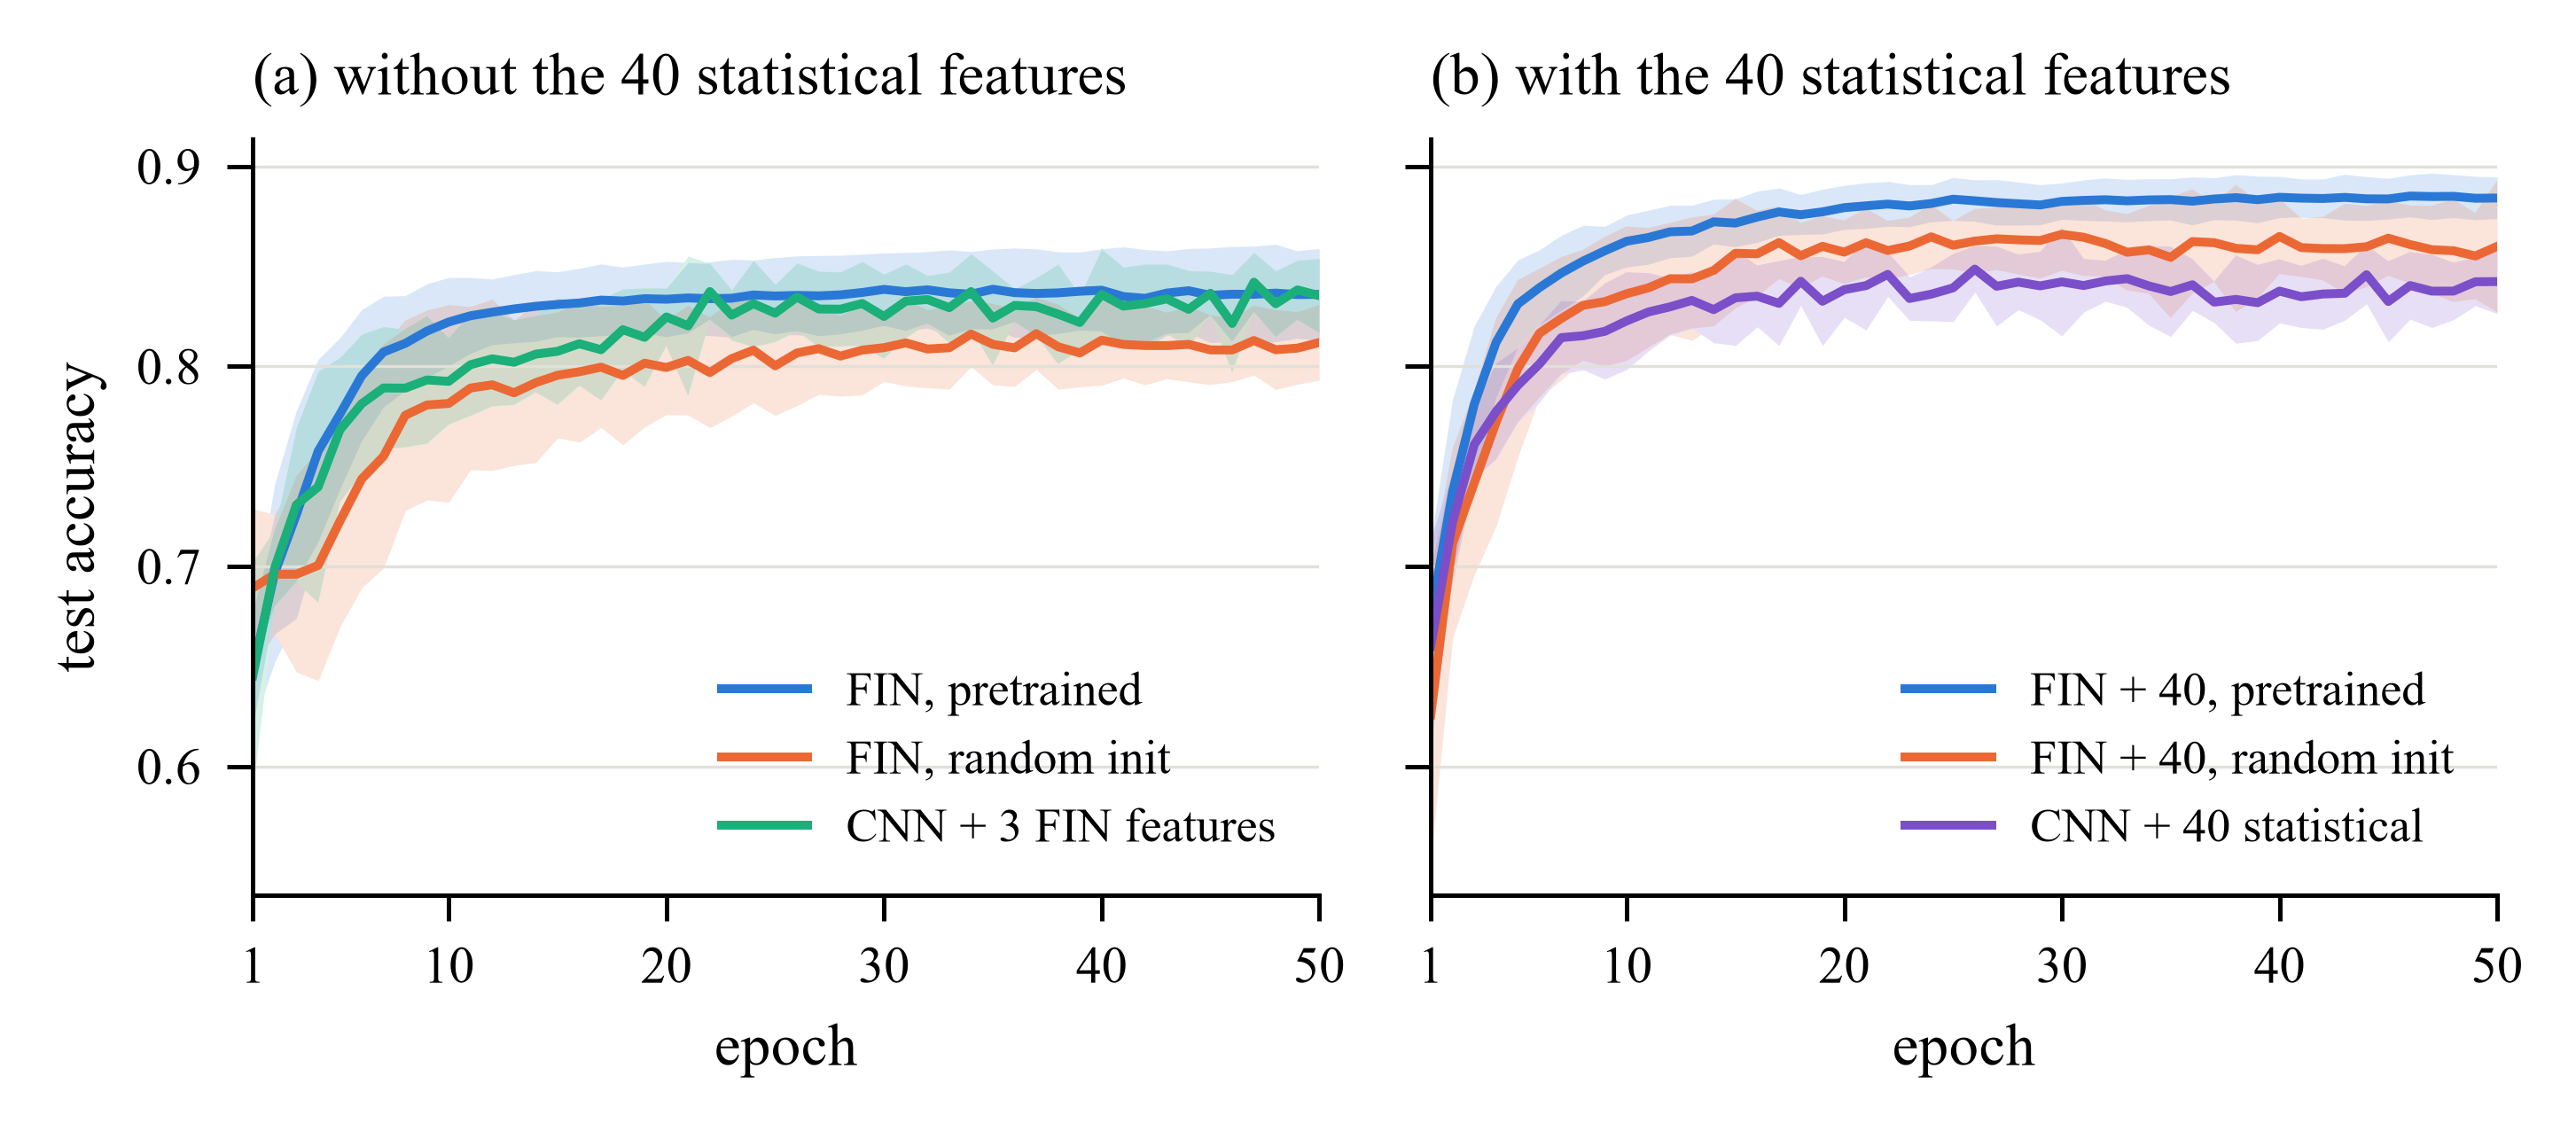

In [6]:
sys.path.insert(0, os.path.join(FIN, "paper-figures"))
from scarcity_curves import plot_panels

CURVES = os.path.join(os.getcwd(), "data_scarcity_curves.npz")
np.savez(CURVES, seeds=np.array(SEEDS), **{KEYS[m]: np.array(c) for m, c in curves.items()})
plot_panels(CURVES)
